# MiniBot Sensör Günlükleri – NumPy & pandas Atölyesi
---
Bu notebook, 7 saatlik eğitim akışı boyunca **NumPy**, **pandas** ve **matplotlib** kullanarak MiniBot sensör verilerini analiz etmeyi adım adım gösterir.


In [35]:
# Gerekli kütüphaneler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Grafiklerin not defteri içinde görünmesi
%matplotlib inline


## 1. Veri Kümesini Yükleyin

In [36]:
df = pd.read_csv('./sample_data/minibot_logs.csv', parse_dates=['timestamp'])
df.head()

,timestamp,robot_id,left_rpm,right_rpm,battery_v,distance_cm,imu_heading_deg
0,2025-06-29 10:00:00.000,MiniBot_1,44.94,90.99,7.41,149.0,358.2
1,2025-06-29 10:00:00.100,MiniBot_1,114.09,2.95,7.40,166.6,357.9
2,2025-06-29 10:00:00.200,MiniBot_1,87.84,2.65,7.43,37.8,359.3
3,2025-06-29 10:00:00.300,MiniBot_1,71.84,38.83,7.41,168.3,358.4
4,2025-06-29 10:00:00.400,MiniBot_1,18.72,58.64,7.38,112.7,358.0


## 2. Zaman Damgasını İndeks Olarak Ayarlama

In [37]:
df = df.set_index('timestamp')
df.index = pd.to_datetime(df.index)
df.sort_index(inplace=True)
df.head()

,robot_id,left_rpm,right_rpm,battery_v,distance_cm,imu_heading_deg
timestamp,,,,,,
2025-06-29 10:00:00.000,MiniBot_1,44.94,90.99,7.41,149.0,358.2
2025-06-29 10:00:00.000,MiniBot_2,104.17,103.33,7.35,13.5,0.6
2025-06-29 10:00:00.100,MiniBot_2,105.75,9.40,7.39,178.8,1.1
2025-06-29 10:00:00.100,MiniBot_1,114.09,2.95,7.40,166.6,357.9
2025-06-29 10:00:00.200,MiniBot_1,87.84,2.65,7.43,37.8,359.3


### Örnek 1 – Temel Özet İstatistikler

In [38]:
# Tüm veri için
print(df.describe())

# Robot bazında
print(df.groupby('robot_id')['left_rpm'].mean())

          left_rpm    right_rpm    battery_v  distance_cm  imu_heading_deg
count  2400.000000  2400.000000  2400.000000  2400.000000      2400.000000
mean     59.441483    58.893550     7.149983   105.151333       151.833792
std      34.811290    34.459339     0.146064    54.654580       172.452116
min       0.030000     0.030000     6.860000    10.000000         0.000000
25%      29.152500    28.770000     7.020000    57.875000         3.600000
50%      59.365000    58.780000     7.150000   105.400000         9.800000
75%      89.850000    87.707500     7.280000   152.700000       355.300000
max     119.970000   119.930000     7.430000   199.900000       360.000000
robot_id
MiniBot_1    59.898675
MiniBot_2    58.984292
Name: left_rpm, dtype: float64


### Örnek 2 – 1 Saniyelik Yeniden Örnekleme

In [39]:
df_1s = df.select_dtypes(include='number').resample('1s').mean()
df_1s.head()

,left_rpm,right_rpm,battery_v,distance_cm,imu_heading_deg
timestamp,,,,,
2025-06-29 10:00:00,65.4535,54.9730,7.3990,110.405,179.500
2025-06-29 10:00:01,52.0955,61.1470,7.3900,88.450,178.800
2025-06-29 10:00:02,55.3515,63.3805,7.3890,120.790,358.215
2025-06-29 10:00:03,54.2880,52.8525,7.3915,101.565,251.240
2025-06-29 10:00:04,51.0410,69.9760,7.3820,103.475,216.060


### Örnek 3 – Eksik Paket Tespiti

In [40]:
expected = 10
missing = df.groupby('robot_id').resample('1S')['left_rpm'].count().reset_index()
missing['lost_packets'] = expected - missing['left_rpm']
missing.head()

,robot_id,timestamp,left_rpm,lost_packets
0,MiniBot_1,2025-06-29 10:00:00,10,0
1,MiniBot_1,2025-06-29 10:00:01,10,0
2,MiniBot_1,2025-06-29 10:00:02,10,0
3,MiniBot_1,2025-06-29 10:00:03,10,0
4,MiniBot_1,2025-06-29 10:00:04,10,0


### Örnek 4 – NumPy ile Lineer Hız

In [41]:
wheel_radius_cm = 3.3  # örnek
rpm_to_cm_s = (2 * np.pi * wheel_radius_cm) / 60
df['linear_speed_cm_s'] = ((df['left_rpm'] + df['right_rpm']) / 2) * rpm_to_cm_s
df[['robot_id', 'linear_speed_cm_s']].head()

,robot_id,linear_speed_cm_s
timestamp,,
2025-06-29 10:00:00.000,MiniBot_1,23.487018
2025-06-29 10:00:00.000,MiniBot_2,35.853426
2025-06-29 10:00:00.100,MiniBot_2,19.896492
2025-06-29 10:00:00.100,MiniBot_1,20.223060
2025-06-29 10:00:00.200,MiniBot_1,15.635550


### Örnek 5 – Batarya Gerilimini Çizme

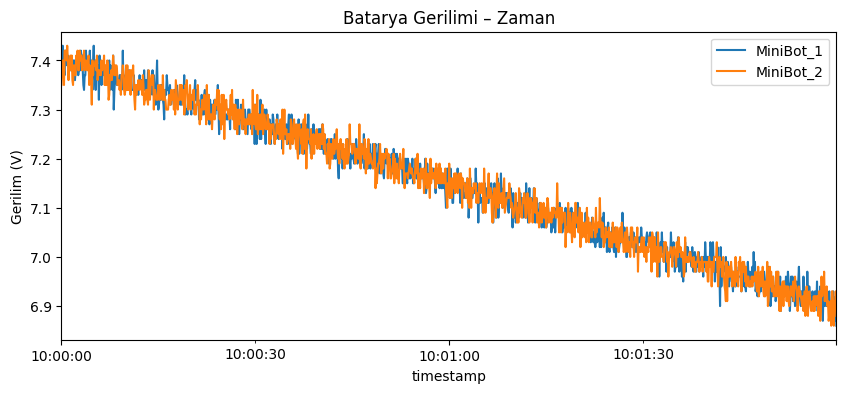

In [42]:
plt.figure(figsize=(10,4))
for rid, sub in df.groupby('robot_id'):
    sub['battery_v'].plot(label=rid)
plt.legend()
plt.ylabel('Gerilim (V)')
plt.title('Batarya Gerilimi – Zaman')
plt.show()

### Örnek 6 – Dönüş Tespiti (RPM Farkı)

In [43]:
df['rpm_diff'] = df['left_rpm'] - df['right_rpm']
turns = df[np.abs(df['rpm_diff']) > 30]
turns.head()

,robot_id,left_rpm,right_rpm,battery_v,distance_cm,imu_heading_deg,linear_speed_cm_s,rpm_diff
timestamp,,,,,,,,
2025-06-29 10:00:00.000,MiniBot_1,44.94,90.99,7.41,149.0,358.2,23.487018,-46.05
2025-06-29 10:00:00.100,MiniBot_2,105.75,9.40,7.39,178.8,1.1,19.896492,96.35
2025-06-29 10:00:00.100,MiniBot_1,114.09,2.95,7.40,166.6,357.9,20.223060,111.14
2025-06-29 10:00:00.200,MiniBot_1,87.84,2.65,7.43,37.8,359.3,15.635550,85.19
2025-06-29 10:00:00.200,MiniBot_2,42.02,8.71,7.40,53.1,2.2,8.765515,33.31


### Örnek 7 – Robot Bazında Özet İstatistikler

In [44]:
summary = df.groupby('robot_id').agg({
    'linear_speed_cm_s': ['mean', 'max'],
    'battery_v': ['mean', 'min'],
    'distance_cm': 'mean'
})
summary

linear_speed_cm_s            battery_v       distance_cm
                       mean        max      mean   min        mean
robot_id                                                          
MiniBot_1         20.678734  40.865994  7.150133  6.86  103.224333
MiniBot_2         20.214918  40.561888  7.149833  6.86  107.078333

### Örnek 8 – Pivot Tablo ile Dakika Bazlı Mesafe

In [45]:
minute_dist = (df.reset_index()
                  .assign(minute=lambda x: x['timestamp'].dt.floor('T'))
                  .groupby(['minute','robot_id'])['distance_cm'].mean()
                  .unstack())
minute_dist.head()

robot_id,MiniBot_1,MiniBot_2
minute,,
2025-06-29 10:00:00,102.118000,107.393500
2025-06-29 10:01:00,104.330667,106.763167


### Örnek 9 – Korelasyon Isı Haritası

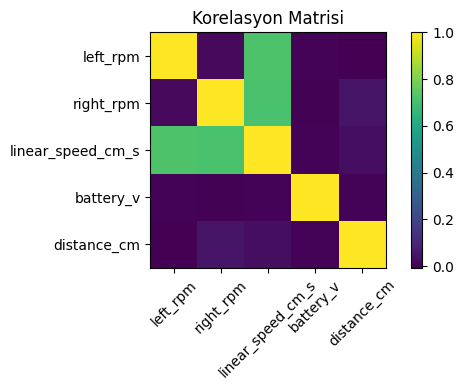

In [46]:
corr = df[['left_rpm','right_rpm','linear_speed_cm_s','battery_v','distance_cm']].corr()
plt.figure(figsize=(6,4))
plt.imshow(corr, cmap='viridis')
plt.xticks(range(len(corr)), corr.columns, rotation=45)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar()
plt.title('Korelasyon Matrisi')
plt.tight_layout()
plt.show()

### Örnek 10 – Batarya Anomali Tespiti

In [47]:
threshold = df['battery_v'].mean() - 1*df['battery_v'].std()
anomalies = df[df['battery_v'] < threshold]
anomalies.head()

,robot_id,left_rpm,right_rpm,battery_v,distance_cm,imu_heading_deg,linear_speed_cm_s,rpm_diff
timestamp,,,,,,,,
2025-06-29 10:01:25.800,MiniBot_1,67.78,78.12,7.0,138.4,359.0,25.209710,-10.34
2025-06-29 10:01:27.400,MiniBot_1,3.05,105.55,7.0,144.2,4.6,18.764733,-102.50
2025-06-29 10:01:27.500,MiniBot_1,18.74,104.47,7.0,75.7,5.9,21.289160,-85.73
2025-06-29 10:01:28.000,MiniBot_2,11.62,69.69,7.0,80.0,2.4,14.049359,-58.07
2025-06-29 10:01:28.600,MiniBot_2,28.03,61.79,7.0,35.0,4.2,15.519782,-33.76


Anomoli görselleştirme

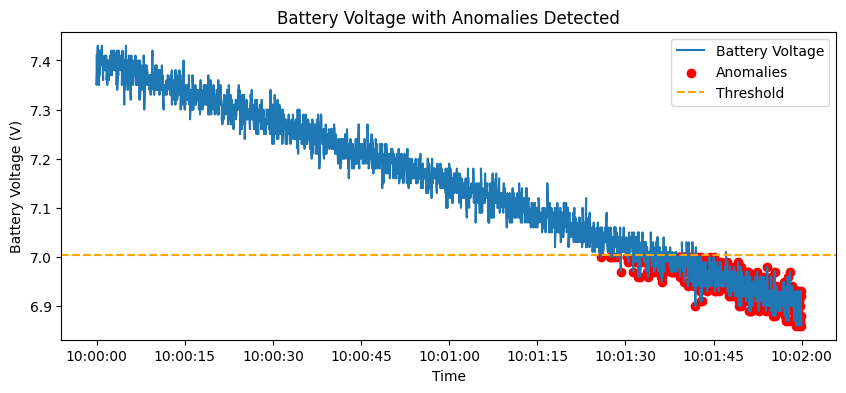

In [48]:
plt.figure(figsize=(10,4))
plt.plot(df.index, df['battery_v'], label='Battery Voltage')
plt.scatter(anomalies.index, anomalies['battery_v'], color='red', label='Anomalies')
plt.axhline(threshold, color='orange', linestyle='--', label='Threshold')
plt.xlabel('Time')
plt.ylabel('Battery Voltage (V)')
plt.title('Battery Voltage with Anomalies Detected')
plt.legend()
plt.show()


## 📝 Quiz & Mini Görevler
1. **Eksik Paket Oranı:** Her robot için toplam kayıp paket sayısını ve %’sini hesaplayın.  
2. **Hız Histogramı:** `linear_speed_cm_s` için 20 binlik histogram çizip yorumlayın.  
3. **Enerji Verimliliği:** Aynı mesafe süresince daha az batarya tüketen robotu bulun.  
4. **Heading Drift:** 30 sn’lik pencerelerde ortalama `imu_heading_deg` değişimini hesaplayın ve ani sapmaları işaretleyin.  
5. **Yeni Sensör:** Veriye “motor sıcaklığı” (random 30‑70 °C) ekleyip, sıcaklığa göre rpm korelasyonunu inceleyin.


Eksik Paket Oranı:

In [49]:
# Örnek 3 – Eksik Paket Oranı Hesaplama (tüm eksik saniyeleri dahil ederek)

expected_per_sec = 10  # Saniyede beklenen paket sayısı

results = []
for rid, sub in df.groupby('robot_id'):
    # Tam zaman aralığını oluştur
    full_idx = pd.date_range(start=sub.index.min(), end=sub.index.max(), freq='1S')
    # Her saniyede alınan paket sayısını hesapla; eksik saniyeleri 0 al
    sec_counts = sub['left_rpm'].resample('1S').count().reindex(full_idx, fill_value=0)

    total_expected = len(sec_counts) * expected_per_sec
    total_received = sec_counts.sum()
    total_lost = total_expected - total_received
    lost_pct = (total_lost / total_expected * 100).round(2)

    results.append({
        'robot_id': rid,
        'total_lost_packets': int(total_lost),
        'total_expected_packets': int(total_expected),
        'lost_packet_percentage': lost_pct
    })

# Sonucu DataFrame olarak özetle ve ekrana yazdır
summary_loss = pd.DataFrame(results)
print(summary_loss)


    robot_id  total_lost_packets  total_expected_packets  \
0  MiniBot_1                   0                    1200   
1  MiniBot_2                   0                    1200   

   lost_packet_percentage  
0                     0.0  
1                     0.0  


Hız Histogramı:

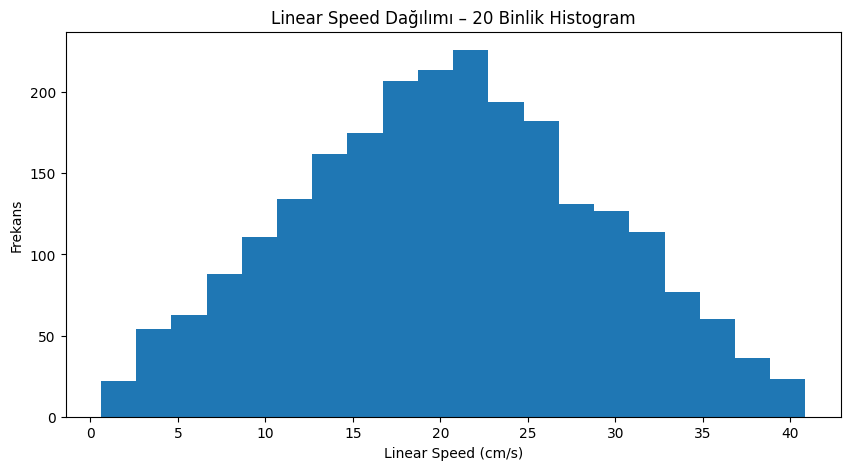

count    2400.00
mean       20.45
std         8.54
min         0.60
25%        14.32
50%        20.36
75%        26.38
max        40.87
Name: linear_speed_cm_s, dtype: float64


In [50]:
# Hız Histogramı – linear_speed_cm_s için 20 bin
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df['linear_speed_cm_s'].dropna(), bins=20)
plt.xlabel('Linear Speed (cm/s)')
plt.ylabel('Frekans')
plt.title('Linear Speed Dağılımı – 20 Binlik Histogram')
plt.show()
print(df['linear_speed_cm_s'].describe().round(2))


Enerji Verimliliği:

In [51]:
# Enerji Verimliliği Hesaplama: cm başına düşen batarya voltajı

# 1. Robot bazında 1 saniyelik ortalamaları al
resampled = (
    df[['robot_id','linear_speed_cm_s','battery_v']]
      .groupby('robot_id')
      .resample('1S')
      .mean()
      .reset_index(level=0)
)

results = []
for rid, sub in resampled.groupby('robot_id'):
    # Toplam kat edilen mesafe (cm) ≈ her saniyedeki hızın toplamı
    total_dist = sub['linear_speed_cm_s'].sum()
    # Batarya voltaj düşüşü: ilk değerden son değeri çıkar
    init_v = sub['battery_v'].iloc[0]
    final_v = sub['battery_v'].iloc[-1]
    drop_v = init_v - final_v

    results.append({
        'robot_id': rid,
        'total_distance_cm': total_dist,
        'battery_drop_V': drop_v,
        'drop_per_cm_V': drop_v / total_dist
    })

eff_df = pd.DataFrame(results)
print(eff_df)

# En verimli robotu bul
best = eff_df.loc[eff_df['drop_per_cm_V'].idxmin()]
print(f"\nEn düşük V/cm ile en verimli robot: {best['robot_id']}")


    robot_id  total_distance_cm  battery_drop_V  drop_per_cm_V
0  MiniBot_1        2481.448109           0.511       0.000206
1  MiniBot_2        2425.790114           0.495       0.000204

En düşük V/cm ile en verimli robot: MiniBot_2


Yeni Sensör:

Motor sıcaklığı ile Left RPM korelasyonu: -0.0071
Motor sıcaklığı ile Right RPM korelasyonu: 0.0164


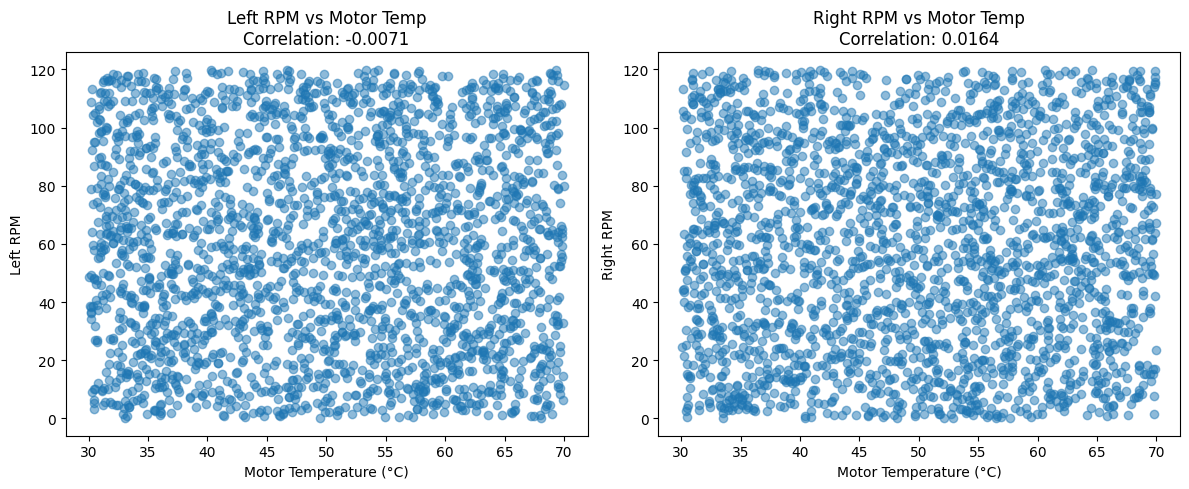

In [52]:
# 1️⃣ Motor sıcaklığı ekleme (random 30‑70 °C)
np.random.seed(42)  # tekrarlanabilirlik için
df['motor_temp_C'] = np.random.uniform(30, 70, size=len(df))

# 2️⃣ Sıcaklık ile left_rpm ve right_rpm arasındaki korelasyonu hesapla
cor_left = df['motor_temp_C'].corr(df['left_rpm'])
cor_right = df['motor_temp_C'].corr(df['right_rpm'])

print(f"Motor sıcaklığı ile Left RPM korelasyonu: {cor_left:.4f}")
print(f"Motor sıcaklığı ile Right RPM korelasyonu: {cor_right:.4f}")

# 3️⃣ Korelasyon scatter plot
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(df['motor_temp_C'], df['left_rpm'], alpha=0.5)
plt.xlabel('Motor Temperature (°C)')
plt.ylabel('Left RPM')
plt.title(f'Left RPM vs Motor Temp\nCorrelation: {cor_left:.4f}')

plt.subplot(1, 2, 2)
plt.scatter(df['motor_temp_C'], df['right_rpm'], alpha=0.5)
plt.xlabel('Motor Temperature (°C)')
plt.ylabel('Right RPM')
plt.title(f'Right RPM vs Motor Temp\nCorrelation: {cor_right:.4f}')

plt.tight_layout()
plt.show()


    robot_id           timestamp  avg_drift_deg   threshold  anomaly
0  MiniBot_1 2025-06-29 10:00:00     265.127090  301.157860    False
1  MiniBot_1 2025-06-29 10:00:30     283.559667  301.157860    False
2  MiniBot_1 2025-06-29 10:01:00     279.256333  301.157860    False
3  MiniBot_1 2025-06-29 10:01:30     266.546000  301.157860    False
4  MiniBot_2 2025-06-29 10:00:00     264.219333  302.067058    False
5  MiniBot_2 2025-06-29 10:00:30     284.832000  302.067058    False
6  MiniBot_2 2025-06-29 10:01:00     278.052667  302.067058    False
7  MiniBot_2 2025-06-29 10:01:30     267.774667  302.067058    False


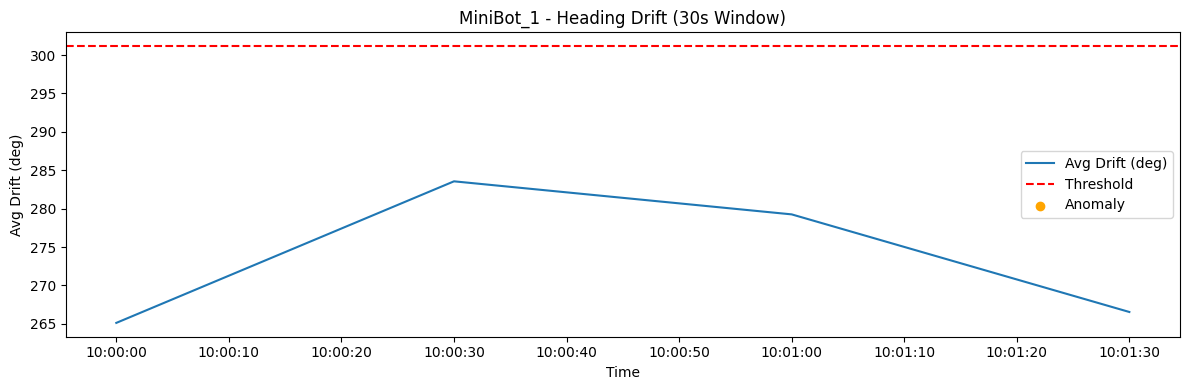

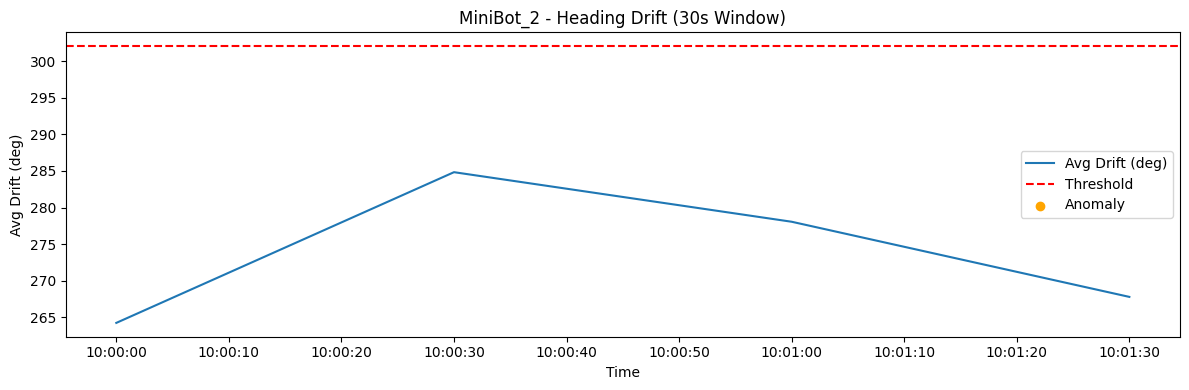

In [56]:
import numpy as np
import matplotlib.pyplot as plt

# 1️⃣ Heading verisini radyana çevir ve unwrap uygula
df['heading_rad'] = np.deg2rad(df['imu_heading_deg'])
df['heading_unwrapped'] = df.groupby('robot_id')['heading_rad'].transform(np.unwrap)

# 2️⃣ Ardışık değerler arasındaki değişimi hesapla ve dereceye çevir
df['delta_heading_deg'] = np.abs(np.degrees(df['heading_unwrapped'].diff()))

# 3️⃣ 30 saniyelik pencerelerde ortalama heading drift hesapla
drift_window = (
    df
    .groupby('robot_id')
    .resample('30S')['delta_heading_deg']  # on='timestamp' kaldırıldı
    .mean()
    .reset_index(name='avg_drift_deg')
)

# 4️⃣ Ani sapma eşiği belirleme (mean + 3*std)
thresholds = drift_window.groupby('robot_id')['avg_drift_deg'].agg(['mean', 'std']).reset_index()
thresholds['threshold'] = thresholds['mean'] + 3 * thresholds['std']

# 5️⃣ Ani sapmaları işaretle
drift_window = drift_window.merge(thresholds[['robot_id', 'threshold']], on='robot_id')
drift_window['anomaly'] = drift_window['avg_drift_deg'] > drift_window['threshold']

# 6️⃣ Sonucu göster
print(drift_window)

# 7️⃣ Görselleştirme
for rid in drift_window['robot_id'].unique():
    sub = drift_window[drift_window['robot_id'] == rid]
    plt.figure(figsize=(12, 4))
    plt.plot(sub['timestamp'], sub['avg_drift_deg'], label='Avg Drift (deg)')
    plt.axhline(sub['threshold'].iloc[0], color='r', linestyle='--', label='Threshold')
    plt.scatter(sub[sub['anomaly']]['timestamp'], sub[sub['anomaly']]['avg_drift_deg'],
                color='orange', label='Anomaly')
    plt.title(f'{rid} - Heading Drift (30s Window)')
    plt.xlabel('Time')
    plt.ylabel('Avg Drift (deg)')
    plt.legend()
    plt.tight_layout()
    plt.show()
